# Romania 2001: competitor count and cutoff step

This notebook runs two descriptive checks beside the existing placement plots. It does not replace the top-program outcome, and it makes **no web requests**.

**Test 1.** Count the other applicants on the same gymnasium page with a strictly higher national exam score. Ties are not counted as better.

**Test 2.** Count how many filled cutoffs in the destination category sit strictly above the program the student entered. Step 0 is the current top filled program. Outside-county placements stay out of that average.

Run **Cell 1** to review settings. Set `RUN_ANALYSIS = True` in **Cell 2** when you choose to build the tables and figures. The default counties are the 22 already plotted. Own-score bands match this morning's run: top 10 percent and 80th-90th.

**Cell 3** is a separate comparison. It keeps gymnasiums that share a town, holds the exam score between the county 90th and 95th percentiles, and measures crowding as that gymnasium's count of county top-tenth applicants. `RUN_WITHIN_TOWN` stays off until you turn it on. One run is already saved under `outputs/romania_2001_within_town_same_score/run_20261019T134256-0400`.

In [4]:
# CELL 1 — VISIBLE RESEARCH SETTINGS
# Nothing is downloaded or analyzed when you run this cell.
from pathlib import Path
import importlib
import sys

def find_analysis_root():
    for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        candidate = parent / "3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis"
        if candidate.is_dir():
            return candidate
        if parent.name == "education_analysis" and (parent / "code").is_dir():
            return parent
    raise FileNotFoundError("Open this notebook from inside the dissertation repository.")

ANALYSIS_ROOT = find_analysis_root()
CODE_DIR = ANALYSIS_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
import EDUCATION_20261009_romania_ct_ph_tm_cj_descriptive_pilot as plot_code
import EDUCATION_20261019_romania_competitor_count_and_cutoff_step as checks
importlib.reload(plot_code)
importlib.reload(checks)

COUNTIES = ("AB", "CS", "GL", "TL", "AR", "SB", "B", "CT", "PH", "TM", "CJ",
            "AG", "BR", "BT", "BV", "DB", "DJ", "GJ", "IL", "OT", "VL", "VN")
TOP_TIERS = (1, 2)
REQUIRE_FULL_PROGRAMS = True
COMBINE_PROGRAM_CATEGORIES = False
# True keeps only the filled math and computer science program as the top outcome.
# Students placed in every other subject stay in the denominator as nonsuccesses.
MATH_CS_ONLY = False
AI_PERCENTILE_CUTS = (90, 80, 50)

settings = plot_code.Settings(
    counties=COUNTIES,
    top_tiers=TOP_TIERS,
    require_full_programs=REQUIRE_FULL_PROGRAMS,
    combine_program_categories=COMBINE_PROGRAM_CATEGORIES,
    math_cs_only=MATH_CS_ONLY,
    ai_percentile_cuts=AI_PERCENTILE_CUTS,
)
settings.validate()
print("Companion code:", checks.__file__)
print("Counties:", COUNTIES)
print("Own-score bands:", AI_PERCENTILE_CUTS, "| top tier used for the rate:", TOP_TIERS[0])
print("Math and computer science only:", MATH_CS_ONLY)
print("Competitor bins:", ", ".join(checks.COMPETITOR_LABELS))
print("No download or outcome analysis has run.")

Companion code: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis/code/EDUCATION_20261019_romania_competitor_count_and_cutoff_step.py
Counties: ('AB', 'CS', 'GL', 'TL', 'AR', 'SB', 'B', 'CT', 'PH', 'TM', 'CJ', 'AG', 'BR', 'BT', 'BV', 'DB', 'DJ', 'GJ', 'IL', 'OT', 'VL', 'VN')
Own-score bands: (90, 80, 50) | top tier used for the rate: 1
Competitor bins: 0, 1-4, 5-9, 10-19, 20 or more
No download or outcome analysis has run.


Building the placement rows used by the existing plots...
Checking the earlier 7 counties: AB, CS, GL, TL, AR, SB, B
Step 1/4 — verifying gymnasium and county source checkpoints...
VERIFIED AB: 168 gymnasium pages, 3041 applicant rows
VERIFIED CS: 171 gymnasium pages, 2606 applicant rows
VERIFIED GL: 190 gymnasium pages, 5345 applicant rows
VERIFIED TL: 103 gymnasium pages, 1953 applicant rows
VERIFIED AR: 136 gymnasium pages, 3164 applicant rows
VERIFIED SB: 152 gymnasium pages, 3236 applicant rows
VERIFIED B: 289 gymnasium pages, 22216 applicant rows
INDEXED 10/41 saved county report sets
INDEXED 20/41 saved county report sets
INDEXED 30/41 saved county report sets
INDEXED 40/41 saved county report sets
INDEXED 41/41 saved county report sets
  AB: 3,041 applicant rows; 85 programs; source counts agree
  CS: 2,606 applicant rows; 63 programs; source counts agree
  GL: 5,345 applicant rows; 74 programs; source counts agree
  TL: 1,953 applicant rows; 42 programs; source counts agree
20

,band,competitor_bin,applicants,gymnasiums,top_tier_successes,top_tier_rate,mean_cutoffs_above,share_at_top_cutoff,cutoff_absent
45,80th–90th (excellence),0,632,622,102,0.161392,4.598716,0.163724,0
46,80th–90th (excellence),1-4,1645,904,303,0.184195,4.881841,0.188433,0
47,80th–90th (excellence),5-9,1364,456,244,0.178886,5.518939,0.184848,0
48,80th–90th (excellence),10-19,2536,465,401,0.158123,5.466856,0.163481,0
49,80th–90th (excellence),20 or more,4776,357,834,0.174623,5.283821,0.178243,0
55,Top 10%,0,1529,1490,544,0.355788,2.653253,0.365526,0
56,Top 10%,1-4,3174,1015,1047,0.329868,2.799026,0.339935,0
57,Top 10%,5-9,2311,554,728,0.315015,2.997777,0.323699,0
58,Top 10%,10-19,2356,348,716,0.303905,2.859604,0.308355,0
59,Top 10%,20 or more,1683,138,474,0.281640,3.326347,0.283832,0


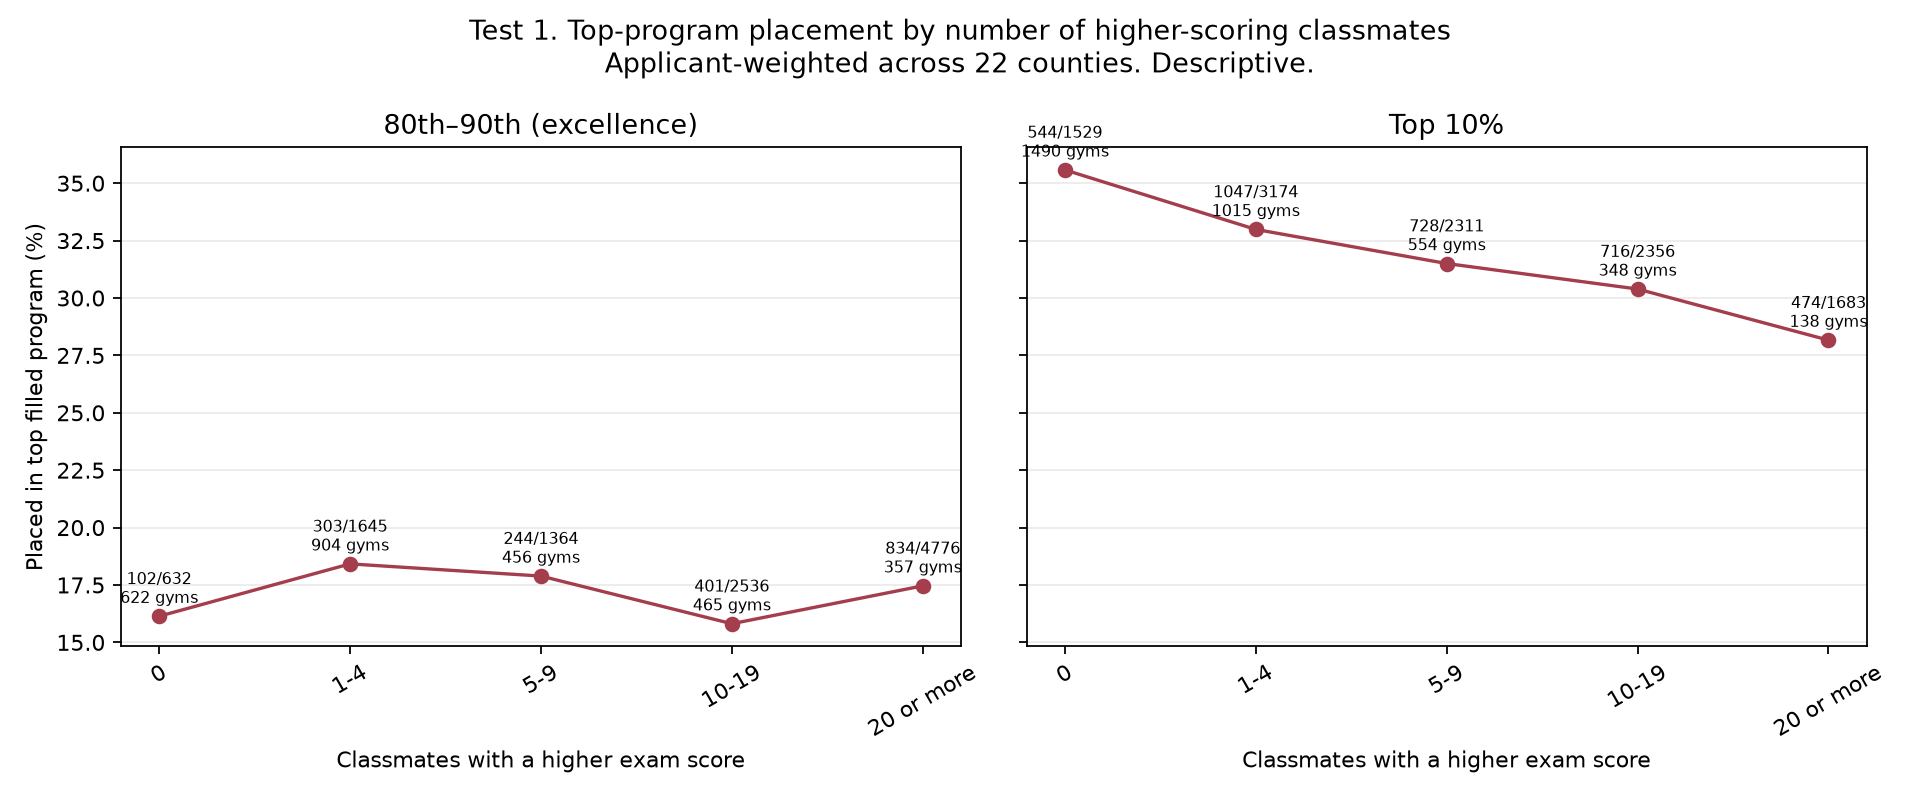

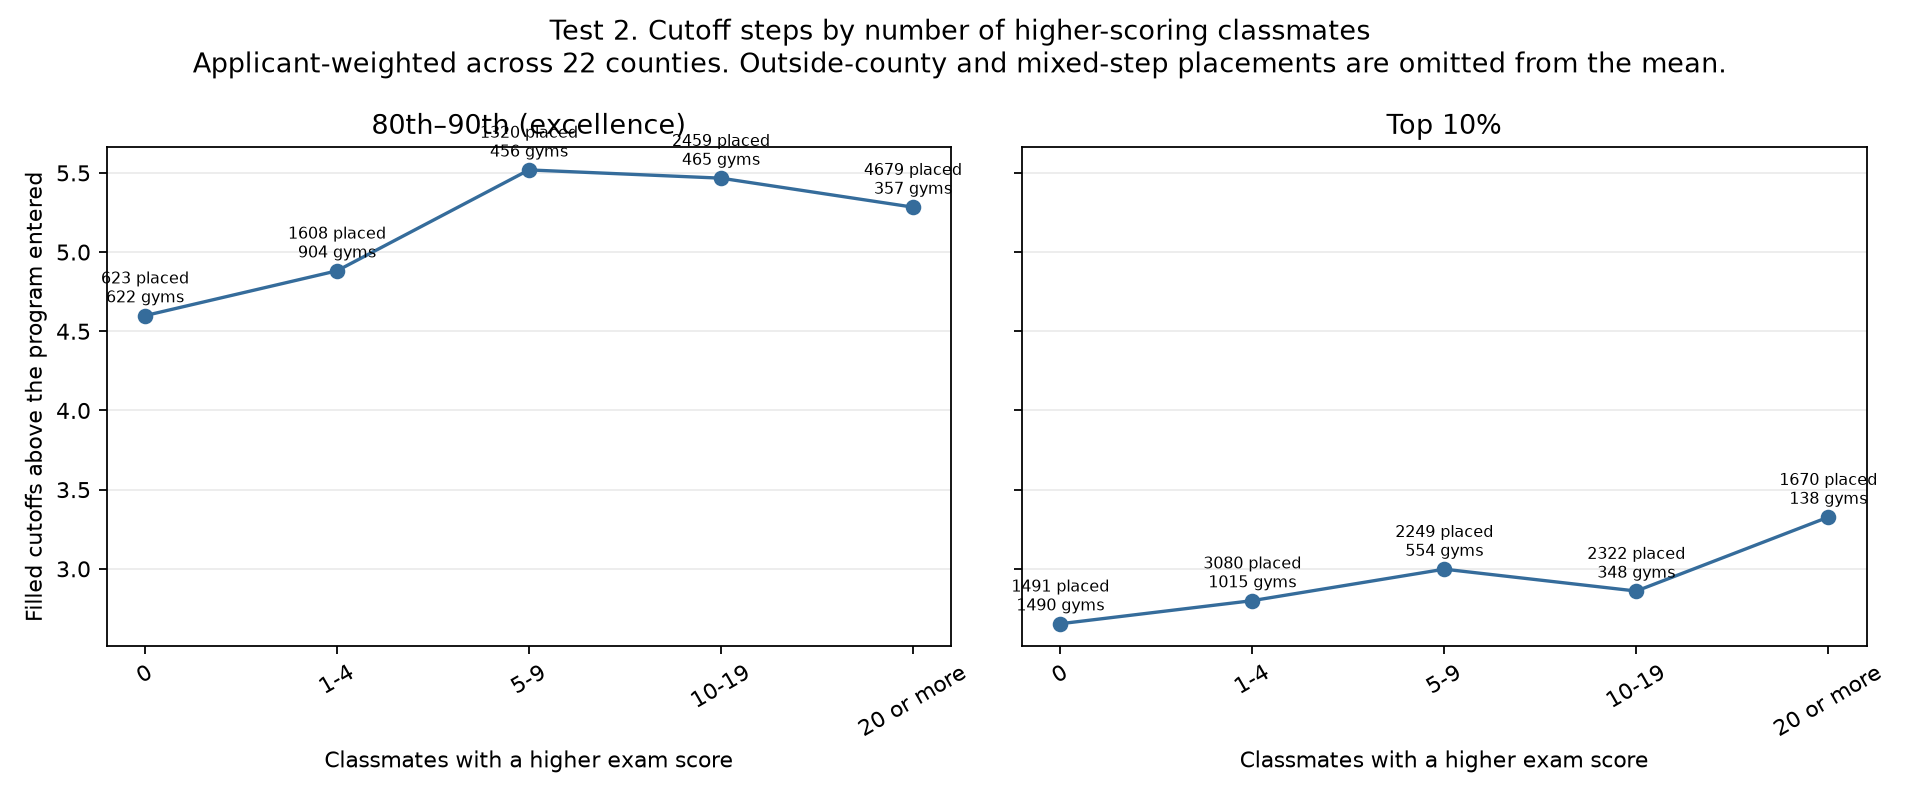

In [6]:
# CELL 2 — RESEARCHER-CONTROLLED RUN
RUN_ANALYSIS = True  # Change to True when you want the tables and figures.

if not RUN_ANALYSIS:
    print("Analysis is off. Set RUN_ANALYSIS = True and rerun this cell.")
else:
    import pandas as pd
    from IPython.display import Image, display
    run_folder = checks.run(settings, run=True)
    print("Results saved:", run_folder)
    table = pd.read_csv(run_folder / "competitor_count_and_cutoff_step.csv")
    high = table["band"].isin(["Top 10%", "80th–90th (excellence)"])
    pooled = table.loc[(table["county"] == "ALL") & high]
    display(pooled[[
        "band", "competitor_bin", "applicants", "gymnasiums",
        "top_tier_successes", "top_tier_rate",
        "mean_cutoffs_above", "share_at_top_cutoff", "cutoff_absent",
    ]])
    display(Image(filename=str(run_folder / "competitor_count_top_tier.png")))
    display(Image(filename=str(run_folder / "competitor_count_cutoff_steps.png")))

In [ ]:
# CELL 3 — WITHIN-TOWN COMPARISON
# Same counties and top-program outcome as Cell 1. Nothing runs until the switch is True.
# The slice is the county 90th percentile up to, but not including, the 95th.
# Crowding is the gymnasium's count of county top-tenth applicants, not a student's own rank.
# A town needs two gymnasiums. Each side of the town needs 15 students to enter the summary.
RUN_WITHIN_TOWN = False

if RUN_WITHIN_TOWN:
    within_town_folder = checks.within_town(
        settings, run=True, slice_low=90, slice_high=95, min_side=15)
    print(within_town_folder)
else:
    print("Within-town comparison is off. Set RUN_WITHIN_TOWN = True to build it.")
    print("A completed run is already saved at")
    print(checks.WITHIN_TOWN_OUTPUTS / "run_20261019T134256-0400")